In [34]:
import geopandas as gpd
from matplotlib import pyplot
import numpy as np
import matplotlib.patches as mpatches
import pandas as pd
from shapely.geometry import box

In [2]:
path_map = 'C:/Users/minttu/Documents/World_Continents/World_Continents.shp'

# Create a map of locations

In [3]:
Map = gpd.read_file(path_map)

In [4]:
Map = Map.to_crs(epsg=4326)

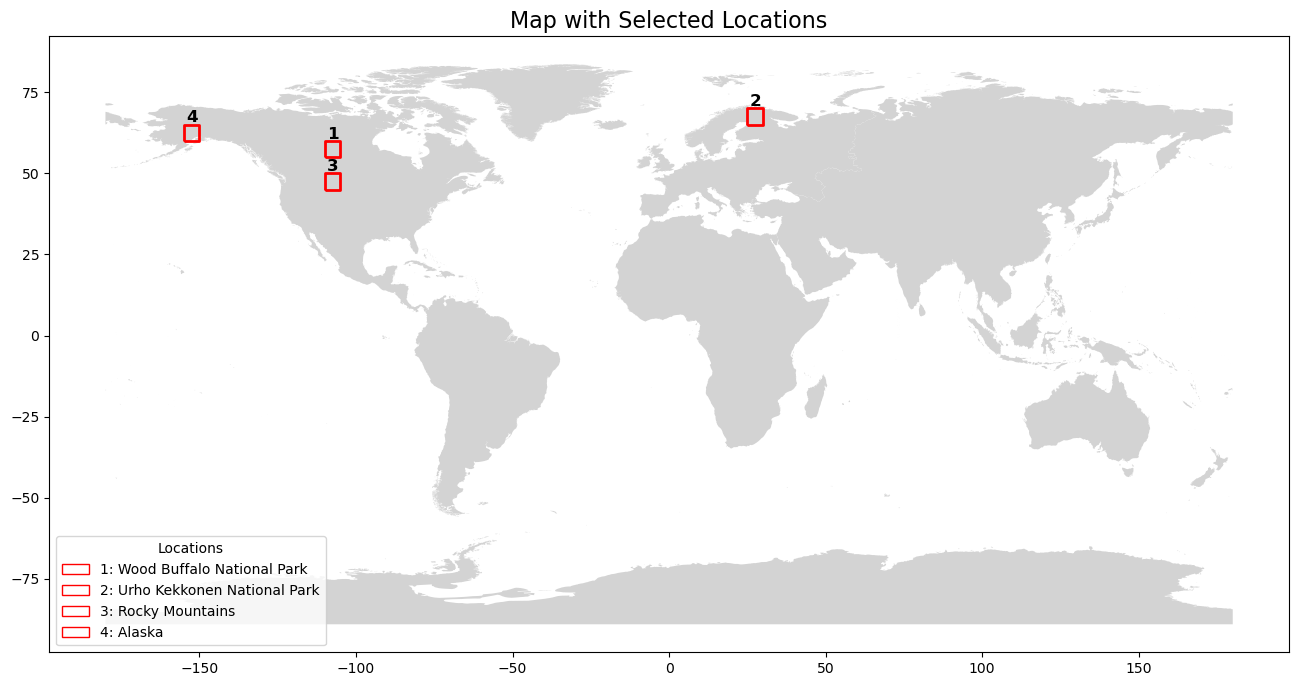

In [40]:
# Convert map to EPSG:4326
Map = Map.to_crs(epsg=4326)

# Create rectangular figure
fig, ax = pyplot.subplots(figsize=(16, 8))

# Plot base map
Map.plot(ax=ax, color='lightgrey')

# Define locations and boundaries
locations = {
    1: {
        "name": "Wood Buffalo National Park",
        "minx": -110.0,
        "miny": 54.999797465533916,
        "maxx": -104.99979746553392,
        "maxy": 60.0,
    },
    2: {
        "name": "Urho Kekkonen National Park",
        "minx": 25.0,
        "miny": 64.99979746553392,
        "maxx": 30.000202534466077,
        "maxy": 70.0,
    },
    3: {
        "name": "Rocky Mountains",
        "minx": -110.0,
        "miny": 44.999797465533916,
        "maxx": -104.99979746553392,
        "maxy": 50.0,
    },
    4: {
        "name": "Alaska",
        "minx": -155.0,
        "miny": 59.999797465533916,
        "maxx": -149.99979746553393,
        "maxy": 65.0,
    }
}

legend_handles = []

# Add boundaries and numbers
for number, bounds in locations.items():

    geom = box(
        bounds["minx"],
        bounds["miny"],
        bounds["maxx"],
        bounds["maxy"]
    )

    gdf = gpd.GeoDataFrame(
        {'name': [bounds["name"]]},
        geometry=[geom],
        crs="EPSG:4326"
    )

    # Plot red boundary
    gdf.boundary.plot(
        ax=ax,
        edgecolor='red',
        linewidth=2
    )

    # Center position for number
    center_x = (bounds["minx"] + bounds["maxx"]) / 2
    center_y = (bounds["miny"] + bounds["maxy"]) / 2

    # Add number ABOVE the box (slightly above maxy)
    ax.text(
        center_x,
        bounds["maxy"] + 0.7,   # shift upward
        str(number),
        fontsize=12,
        color='black',
        ha='center',
        fontweight='bold'
    )

    # Legend entry
    legend_handles.append(
        mpatches.Patch(
            facecolor='none',
            edgecolor='red',
            label=f"{number}: {bounds['name']}"
        )
    )

# Add legend
ax.legend(
    handles=legend_handles,
    loc='lower left',
    fontsize=10,
    title="Locations"
)

# Make map rectangular
ax.set_aspect('auto')

# Title
pyplot.title("Map with Selected Locations", fontsize=16)

pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Map_with_selected_locations.png")
pyplot.show()

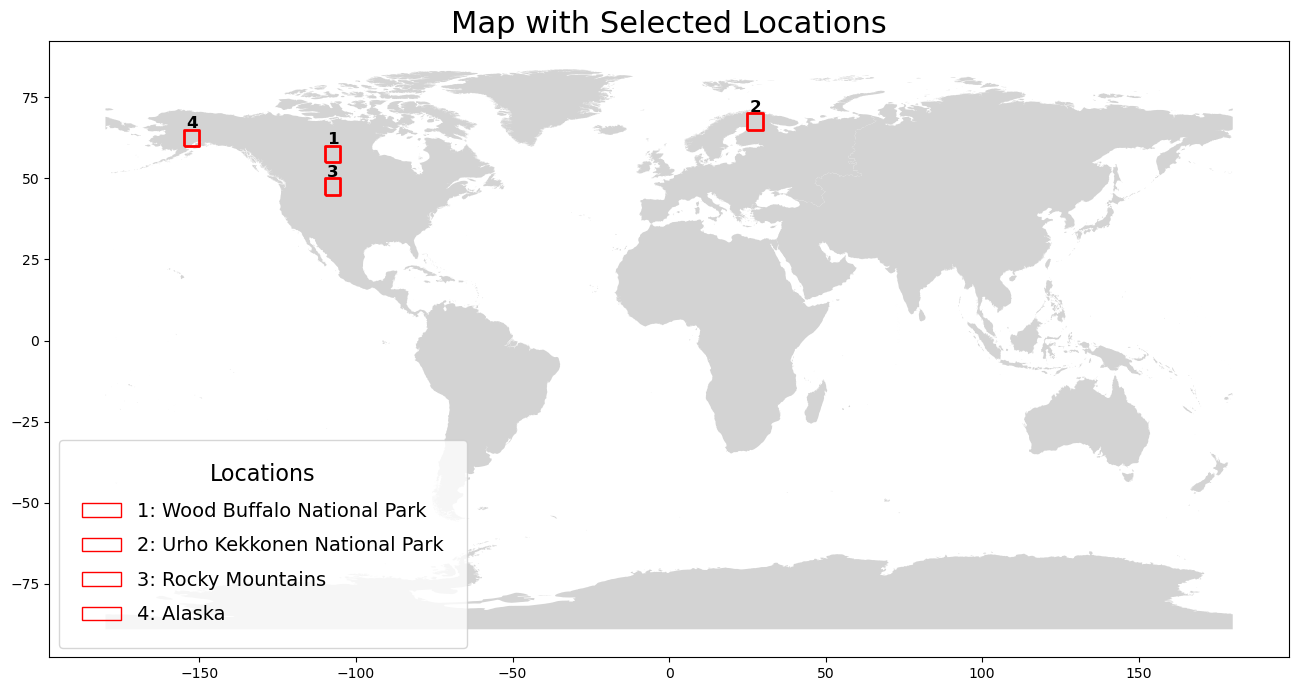

In [44]:
import geopandas as gpd
import matplotlib.pyplot as pyplot
import matplotlib.patches as mpatches
from shapely.geometry import box

# Convert map to EPSG:4326
Map = Map.to_crs(epsg=4326)

# Create rectangular figure
fig, ax = pyplot.subplots(figsize=(16, 8))

# Plot base map
Map.plot(ax=ax, color='lightgrey')

# Define locations and boundaries
locations = {
    1: {
        "name": "Wood Buffalo National Park",
        "minx": -110.0,
        "miny": 54.999797465533916,
        "maxx": -104.99979746553392,
        "maxy": 60.0,
    },
    2: {
        "name": "Urho Kekkonen National Park",
        "minx": 25.0,
        "miny": 64.99979746553392,
        "maxx": 30.000202534466077,
        "maxy": 70.0,
    },
    3: {
        "name": "Rocky Mountains",
        "minx": -110.0,
        "miny": 44.999797465533916,
        "maxx": -104.99979746553392,
        "maxy": 50.0,
    },
    4: {
        "name": "Alaska",
        "minx": -155.0,
        "miny": 59.999797465533916,
        "maxx": -149.99979746553393,
        "maxy": 65.0,
    }
}

legend_handles = []

# Add boundaries and numbers
for number, bounds in locations.items():

    geom = box(
        bounds["minx"],
        bounds["miny"],
        bounds["maxx"],
        bounds["maxy"]
    )

    gdf = gpd.GeoDataFrame(
        {'name': [bounds["name"]]},
        geometry=[geom],
        crs="EPSG:4326"
    )

    # Draw red boundary
    gdf.boundary.plot(
        ax=ax,
        edgecolor='red',
        linewidth=2
    )

    # Center position
    center_x = (bounds["minx"] + bounds["maxx"]) / 2

    # Number above box
    offset = (bounds["maxy"] - bounds["miny"]) * 0.1
    ax.text(
        center_x,
        bounds["maxy"] + offset,
        str(number),
        fontsize=12,
        color='black',
        ha='center',
        fontweight='bold'
    )

    # Legend entry (only number + name)
    legend_handles.append(
        mpatches.Patch(
            facecolor='none',
            edgecolor='red',
            label=f"{number}: {bounds['name']}"
        )
    )

# Add large legend
ax.legend(
    handles=legend_handles,
    loc='lower left',
    fontsize=14,
    title="Locations",
    title_fontsize=16,
    frameon=True,
    borderpad=1.2,
    labelspacing=0.8
)

# Make map rectangular
ax.set_aspect('auto')

# Title
pyplot.title("Map with Selected Locations", fontsize=22)

pyplot.savefig("C:/Users/minttu/Documents/GitHub/Bern_University_transmissivity_maps/Figures/Map_with_selected_locations.png")
pyplot.show()